- 实验

In [1]:
import time
import torch
import numpy as np
import torch.nn as nn
import matplotlib.pyplot as plt
import torch.optim as optim
import torch.nn.functional as F
from torch.optim import lr_scheduler

from utils.metrics import PIVmetric
from utils.visualizer import plot_flow_field

# 数据加载：事件、光流
from generator.flow import FlowManager
from generator.images import config_events
from generator.loader import EventManager

# 检查CUDA是否可用
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


In [2]:
class GaussianRep(nn.Module):
    def __init__(self, num_gaussians, H, W, enable_jacobian=False, enable_opacity = False, device='cuda'):
        super().__init__()

        self.num_gaussians   = num_gaussians
        self.H, self.W       = H, W
        self.device          = device
        self.enable_jacobian = enable_jacobian

        # ==========================================================
        # 参数说明
        #   mu            : [N, 2]，Gaussian 中心，顺序 (h, w)
        #   log_scale     : [N, 2]，对数尺度，顺序 (scale_h, scale_w)
        #   local_velocity: [N, 2]，局部坐标系下的速度向量，顺序 (vel_h_local, vel_w_local)
        #                   经旋转矩阵 R 变换后得到全局 (h,w) 坐标系下的速度 (vel_h, vel_w)
        #   J_params      : [N, 4]，仿射雅可比的四个自由度 (a, b, c, d)，见 forward 中说明
        # ==========================================================
        self.mu = nn.Parameter(torch.rand(num_gaussians, 2, device=device) * H)          # (h, w)

        self.log_scale = nn.Parameter(torch.stack([
            torch.ones(num_gaussians, device=device) * np.log(100.0),
            torch.ones(num_gaussians, device=device) * np.log(100.0)
        ], dim=1))                                                      # (scale_h, scale_w)

        self.rotation       = nn.Parameter(torch.zeros(num_gaussians, 1, device=device))
        self.local_velocity = nn.Parameter(3 * torch.randn(num_gaussians, 2, device=device))      # (vel_h_local, vel_w_local)

        if enable_jacobian:
            self.J_params = nn.Parameter(0.01 * torch.randn(num_gaussians, 4, device=device))
            # self.J_params = nn.Parameter(torch.zeros(num_gaussians, 4, device=device))
        else:
            self.register_parameter("J_params", None)

        if enable_opacity:
            self.opacity_logit  = nn.Parameter(torch.zeros(num_gaussians, 1, device=device))
        else:
            self.register_parameter("opacity_logit", None)
            
        # ----------------------------------------------------------
        # 像素坐标网格: [H, W, 2]，最后一维顺序 (h, w)
        # ----------------------------------------------------------
        h_coords, w_coords = torch.meshgrid(
            torch.arange(H, dtype=torch.float32, device=device),
            torch.arange(W, dtype=torch.float32, device=device),
            indexing='ij'
        )
        self.register_buffer('grid', torch.stack([h_coords, w_coords], dim=-1))

    # ==============================================================
    # Gaussian geometry
    # ==============================================================
    def compute_gaussian_geometry(self):
        """
        返回:
            Sigma_inv : [N, 2, 2]，精度矩阵，坐标顺序 (h, w)
            R         : [N, 2, 2]，旋转矩阵，作用在 (h, w) 列向量上
        """
        scale = torch.exp(self.log_scale)       # [N, 2]，(scale_h, scale_w)

        theta = self.rotation.squeeze(-1)       # [N]
        cos_t = torch.cos(theta)
        sin_t = torch.sin(theta)

        # R 将局部 (h,w) 向量旋转到全局 (h,w) 坐标系
        R = torch.stack([
            torch.stack([ cos_t, -sin_t], dim=-1),
            torch.stack([ sin_t,  cos_t], dim=-1)
        ], dim=-2)                              # [N, 2, 2]

        inv_s2_h = 1.0 / (scale[:, 0] ** 2 + 1e-6)
        inv_s2_w = 1.0 / (scale[:, 1] ** 2 + 1e-6)

        # Sigma_inv = R @ diag(inv_s2_h, inv_s2_w) @ R^T
        # 手写展开，行列均对应 (h, w) 轴
        Sigma_inv = torch.zeros(self.num_gaussians, 2, 2, device=self.device)
        Sigma_inv[:, 0, 0] = R[:, 0, 0] ** 2 * inv_s2_h + R[:, 0, 1] ** 2 * inv_s2_w
        Sigma_inv[:, 0, 1] = R[:, 0, 0] * R[:, 1, 0] * inv_s2_h + R[:, 0, 1] * R[:, 1, 1] * inv_s2_w
        Sigma_inv[:, 1, 0] = Sigma_inv[:, 0, 1]
        Sigma_inv[:, 1, 1] = R[:, 1, 0] ** 2 * inv_s2_h + R[:, 1, 1] ** 2 * inv_s2_w

        return Sigma_inv, R

    # ==============================================================
    # forward
    # ==============================================================
    def forward(self):
        """
        返回:
            flow      : [2, H, W]
                        通道 0 ，竖直方向速度（h 轴正方向）
                        通道 1 ，水平方向速度（w 轴正方向）
            weight_sum: [1, H, W]，各像素 Gaussian 权重之和
        """
        H, W = self.H, self.W

        Sigma_inv, R = self.compute_gaussian_geometry()

        if self.opacity_logit is not None:
           opacity = torch.sigmoid(self.opacity_logit)   # [N, 1]
        else:
            opacity = torch.ones(self.num_gaussians, 1, device=device)

        # local_velocity [N, 2] = (vel_h_local, vel_w_local)
        # 经 R 旋转到全局 (h, w) 坐标系，得到 (vel_h, vel_w)
        velocity_global_hw = torch.matmul(R, self.local_velocity.unsqueeze(-1)).squeeze(-1)          # [N, 2]，(vel_h, vel_w)

        # ----------------------------------------------------------
        # Mahalanobis 距离
        #   pixels : [H*W, 2]，(h, w)
        #   delta  : [H*W, N, 2]，(dh, dw)
        # ----------------------------------------------------------
        pixels = self.grid.reshape(-1, 2)
        delta  = pixels.unsqueeze(1) - self.mu.unsqueeze(0)   # [H*W, N, 2]

        dh = delta[..., 0]   # [H*W, N]
        dw = delta[..., 1]   # [H*W, N]

        inv_hh = Sigma_inv[:, 0, 0]
        inv_hw = Sigma_inv[:, 0, 1]
        inv_ww = Sigma_inv[:, 1, 1]

        mahalanobis = (
            dh * dh * inv_hh.unsqueeze(0) +
            2 * dh * dw * inv_hw.unsqueeze(0) +
            dw * dw * inv_ww.unsqueeze(0)
        )                                              # [H*W, N]

        gaussian_weight = torch.exp(-0.5 * mahalanobis)                    # [H*W, N]
        weight = gaussian_weight * opacity.squeeze(-1).unsqueeze(0)         # [H*W, N]

        # ----------------------------------------------------------
        # 仿射速度场（Jacobian 项）
        #
        # J_local 定义在局部 (h,w) 坐标系，输入输出均为 (h,w) 向量：
        #
        #   J_local = [[ a,  b ],    行0：vel_h 对 (h,w) 的偏导
        #              [ c, -a ]]    行1：vel_w 对 (h,w) 的偏导
        #
        #   [0,0] = a  = ∂vel_h/∂h
        #   [0,1] = b  = ∂vel_h/∂w
        #   [1,0] = c  = ∂vel_w/∂h
        #   [1,1] = -a = ∂vel_w/∂w
        #
        # 无散条件（连续性方程）：
        #   ∂vel_h/∂h + ∂vel_w/∂w = a + (−a) = 0  ✅ 由参数化自动保证
        #
        # 旋转到全局坐标后：J_global = R @ J_local @ R^T
        # J_global 同样作用在全局 (h,w) 向量，输出全局 (vel_h, vel_w)。
        #
        # 最终输出通道为 (u, v) = (vel_w, vel_h)，对应的雅可比对角元为：
        #   ∂u/∂w = ∂vel_w/∂w = J_local[1,1] = −a   （水平速度沿水平方向的变化率）
        #   ∂v/∂h = ∂vel_h/∂h = J_local[0,0] =  a   （竖直速度沿竖直方向的变化率）
        # 两者均为 a 的线性函数；a 初始化为 ~0，训练中趋向 0 时两对角元同时趋零，
        # 对应速度场在各自主方向上无拉伸/压缩（纯旋转或剪切模式）。
        # 非对角元 b = ∂v/∂w（竖直速度随水平位置变化），
        #            c = ∂u/∂h（水平速度随竖直位置变化），自由优化。
        # ----------------------------------------------------------
        if self.J_params is not None:
            a, b, c, d = self.J_params.unbind(-1)         # 各 [N]

            J_local = torch.stack([
                torch.stack([ a, b], dim=-1),         # [∂vel_h/∂h, ∂vel_h/∂w]
                torch.stack([ c, d], dim=-1)          # [∂vel_w/∂h, ∂vel_w/∂w]
            ], dim=-2)                                 # [N, 2, 2]

            # 旋转到全局 (h,w) 坐标系
            J_global = torch.bmm(R, torch.bmm(J_local, R.transpose(1, 2)))  # [N, 2, 2]

            # affine_velocity[p, n, :] = J_global[n] @ delta[p, n]
            # 输出为全局 (vel_h_affine, vel_w_affine)
            affine_velocity = torch.einsum('nij,hnj->hni', J_global, delta) # [H*W, N, 2]
        else:
            affine_velocity = 0.0

        # total_velocity: [H*W, N, 2]，(vel_h, vel_w)
        total_velocity = velocity_global_hw.unsqueeze(0) + affine_velocity

        # ----------------------------------------------------------
        # 加权聚合
        # ----------------------------------------------------------
        weighted_velocity = (total_velocity * weight.unsqueeze(-1)).sum(dim=1)  # [H*W, 2]
        weight_sum        = weight.sum(dim=1, keepdim=True) + 1e-31             # [H*W, 1]

        # flow_hw: [H, W, 2]，最后一维 (vel_h, vel_w)
        flow_hw = (weighted_velocity / weight_sum).reshape(H, W, 2)

        # return flow, weight_sum.reshape(1, H, W)
        return flow_hw.permute(2, 0, 1), weight_sum.reshape(1, H, W)

In [3]:
def create_optimizer(model, lr_mu=0.5):

    param_groups = []

    def add_param(name, param, lr):
        if param is not None and param.requires_grad:
            param_groups.append({
                'params': [param],
                'lr': lr,
                'name': name
            })

    add_param("mu", model.mu, lr_mu)
    add_param("scale", model.log_scale, 0.01)
    add_param("rotation", model.rotation, 0.01)
    
    add_param("velocity", model.local_velocity, 0.1)

    if hasattr(model, 'J_params') and model.J_params is not None:
        add_param("jacobian", model.J_params, 0.001)

    if hasattr(model, 'J_params') and model.opacity_logit is not None:
        add_param("opacity", model.opacity_logit, 0.005)

    return optim.Adam(param_groups, betas=(0.9, 0.999), eps=1e-15)

In [4]:
def train(flowgt, init_n, enable_jacobian, enable_opacity, interations, device='cuda'):
    loss_list = []
    model = GaussianRep(num_gaussians=init_n, H=256, W=256, enable_jacobian=enable_jacobian, enable_opacity=enable_opacity, device=device)
    optimizer = create_optimizer(model)

    lr_lambda_mu = lambda step: (1 / 10) ** (step / interations)
    lr_lambda_velocity = lambda step: (1 / 10) ** (step / interations)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=[lr_lambda_mu if g["name"] == "mu" else (lambda s: 1.0) for g in optimizer.param_groups])
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=[lr_lambda_velocity if g["name"] == "velocity" else (lambda s: 1.0) for g in optimizer.param_groups])
    
    print(f"开始训练 | 初始高斯数: {model.num_gaussians}")

    for i in range(interations):
        optimizer.zero_grad(set_to_none=True)
        pred_flow, weight_map = model()
        loss_data = F.mse_loss(pred_flow, flowgt)
        total_loss = loss_data
        total_loss.backward()
        optimizer.step()
        scheduler.step()
        loss_list.append(total_loss.item())

        if i % 500 == 0:
            print(f"Iter {i:04d} | total={total_loss.item():.9f}")

    with torch.no_grad():
        pred_flow, weight_map = model()

    print("训练结束")

    plt.figure(figsize=(12, 4))
    plt.plot(loss_list)
    plt.xlabel("Iteration")
    plt.ylabel("MSE Loss")
    plt.yscale("log")
    plt.title("Training Loss Curve")
    plt.grid(True)
    plt.show()

    return pred_flow.detach().cpu().numpy(), model, weight_map

In [5]:
flow0 = FlowManager(mode="analytical", name="solid_rot", x_c=128, y_c=128, omega=0.005525*5)
flow1 = FlowManager(mode="analytical", name="uniform", uc=4/np.sqrt(2), vc=4/np.sqrt(2))
flow2 = FlowManager(mode="analytical", name="one_shear", vmax=5, vmin=0.0, p=256)
flow3 = FlowManager(mode="analytical", name="cellular_flow", vmax=5, p=256)
flow4 = FlowManager(mode="analytical", name="lamb_oseen", x_c=128, y_c=128, Gamma=3e3, rc=60)
flow5 = FlowManager(mode="data", data_path="./data/datasets/JHTDB_isotropic1024_hd_00001_flow.npz")

In [6]:
def test(flow_index, output_file):
    flow_func = globals()[f"flow{flow_index}"].evaluate

    cfg_evts = config_events()
    cfg_evts.time_length=5
    cfg_evts.d = 0.5
    cfg_evts.density = 0.05
    
    event_loader = EventManager(source_type="simulator", path=None, cfg=cfg_evts, flow_func=flow_func)
    evts, (u, v) = event_loader.load()
    flowgt = torch.stack([u, v], dim=0).to(device)
    
    events = evts[(evts[:, 2] > 0) & (evts[:, 2] < 3)]
    h_gt = u.cpu().numpy()
    w_gt = v.cpu().numpy()

    # plot_flow_field(u, torch.zeros_like(u), output_file=None, colorbar_flag=True, step=1, quiver_step=16, scale=None, figsize=(5, 3))
    # plot_flow_field(torch.zeros_like(v), v, output_file=None, colorbar_flag=True, step=1, quiver_step=16, scale=None, figsize=(5, 3))
    
    plot_flow_field(u, v, output_file=None, colorbar_flag=True, step=1, quiver_step=16, scale=None, figsize=(5, 3))

    # for enable_jacobian in [1, 0]:
    for enable_jacobian in [1]:
        pred_hw, model, weight_map = train(flowgt=flowgt, init_n = 3, interations=4001, enable_jacobian=enable_jacobian, enable_opacity=True)
        vel_h, vel_w = pred_hw[0], pred_hw[1]
        if enable_jacobian:
            out_model = model
        
        PIVmetric(vel_h, vel_w, h_gt, w_gt)
        
        if output_file is not None:
            output_file = f"{flow_index}_{enable_jacobian}.png"
            
        plot_flow_field(vel_h, vel_w, output_file=output_file, v_min = 0, v_max = 5, colorbar_flag=True, step=1, quiver_step=16, 
                scale=None, slFlag=False, figsize=(5, 3), cbar_ticks=[0.0, 1.0, 2.0, 3.0, 4.0, 5.0], cbar_tick_size=12)

    return out_model

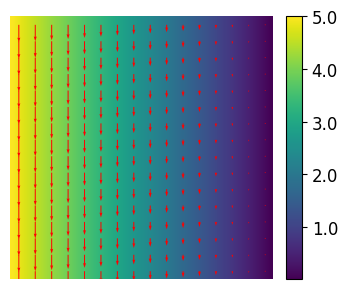

开始训练 | 初始高斯数: 3
Iter 0000 | total=6.574042797
Iter 0500 | total=0.000527809
Iter 1000 | total=0.000247730
Iter 1500 | total=0.000146383
Iter 2000 | total=0.000089538
Iter 2500 | total=0.000053129
Iter 3000 | total=0.000030085
Iter 3500 | total=0.000016558
Iter 4000 | total=0.000009073
训练结束


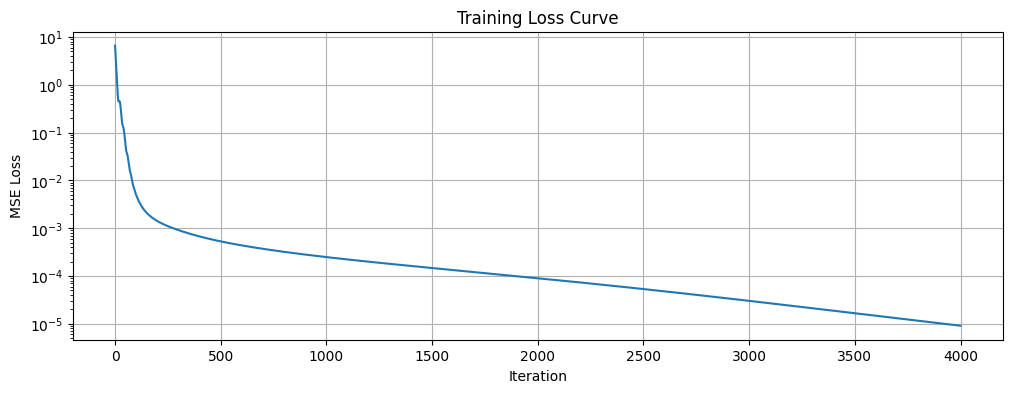

0.0043(RMSE)	0.0036(AEE)	0.0040(AAE,rad)	0.9989(SSIM)	1.0000(MoC)	0(epe1)	0(epe2)	0(epe3)	


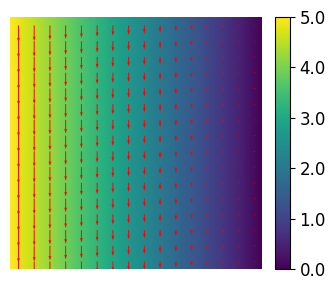

In [7]:
model0 = test(flow_index=2, output_file = None)
# print(model0.J_params)
# print(torch.exp(model0.log_scale))

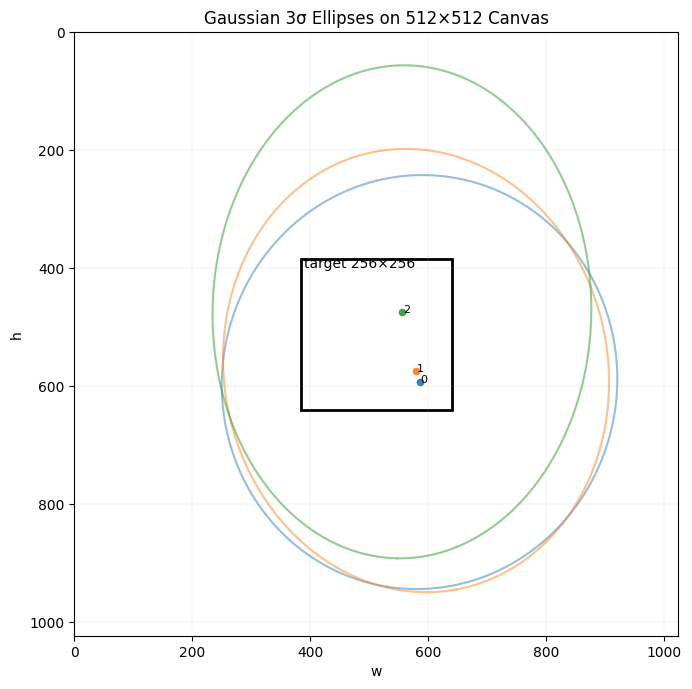

In [8]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

def plot_gaussian_3sigma_canvas(model, H=256, W=256, canvas_H=512, canvas_W=512, ax=None, show_id=True, show_center=True, show_bbox=False, title="Gaussian 3σ Ellipses on 512×512 Canvas"):
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 7))
    else:
        fig = ax.figure

    offset_h = (canvas_H - H) / 2
    offset_w = (canvas_W - W) / 2

    with torch.no_grad():
        mu = model.mu.detach().cpu()
    
        if hasattr(model, "log_scale"):
            scale = torch.exp(model.log_scale.detach().cpu())
        elif hasattr(model, "log_scales"):
            scale = torch.exp(model.log_scales.detach().cpu())
        elif hasattr(model, "scale"):
            scale = model.scale.detach().cpu()
        else:
            raise AttributeError("model 中没有找到 log_scale / log_scales / scale")
    
        if hasattr(model, "rotation"):
            theta = model.rotation.detach().cpu().reshape(-1)
        elif hasattr(model, "rotations"):
            theta = model.rotations.detach().cpu().reshape(-1)
        else:
            theta = torch.zeros(mu.shape[0])
    
        opacity_logit = getattr(model, "opacity_logit", None)
        opacity = getattr(model, "opacity", None)
    
        if opacity_logit is not None:
            alpha = torch.sigmoid(opacity_logit.detach().cpu()).reshape(-1)
        elif opacity is not None:
            alpha = opacity.detach().cpu().reshape(-1)
        else:
            alpha = torch.ones(mu.shape[0])

    t = np.linspace(0, 2 * np.pi, 240)

    for i in range(mu.shape[0]):
        mh, mw = mu[i].numpy()
        sh, sw = scale[i].numpy()
        th = float(theta[i])
        a = float(alpha[i])

        local_h = 3.0 * sh * np.cos(t)
        local_w = 3.0 * sw * np.sin(t)

        c, s = np.cos(th), np.sin(th)
        dh = c * local_h - s * local_w
        dw = s * local_h + c * local_w

        ellipse_h = mh + dh + offset_h
        ellipse_w = mw + dw + offset_w
        center_h = mh + offset_h
        center_w = mw + offset_w

        ax.plot(ellipse_w, ellipse_h, linewidth=1.5, alpha=max(0.25, min(1.0, a)))

        if show_center:
            ax.scatter([center_w], [center_h], s=20, alpha=0.9)

        if show_id:
            ax.text(center_w + 2, center_h + 2, str(i), fontsize=8)

        if show_bbox:
            h_min, h_max = ellipse_h.min(), ellipse_h.max()
            w_min, w_max = ellipse_w.min(), ellipse_w.max()
            ax.plot([w_min, w_max, w_max, w_min, w_min], [h_min, h_min, h_max, h_max, h_min], "--", linewidth=0.8, alpha=0.5)

    # 中间的目标 256×256 区域
    rect = Rectangle((offset_w, offset_h), W, H, fill=False, linewidth=2.0, linestyle="-")
    ax.add_patch(rect)
    ax.text(offset_w + 5, offset_h + 15, f"target {H}×{W}", fontsize=10)

    ax.set_xlim(0, canvas_W - 1)
    ax.set_ylim(canvas_H - 1, 0)
    ax.set_aspect("equal")
    ax.set_xlabel("w")
    ax.set_ylabel("h")
    ax.set_title(title)
    ax.grid(True, linewidth=0.3, alpha=0.4)
    plt.tight_layout()
    return fig, ax

plot_gaussian_3sigma_canvas(model0, H=256, W=256, canvas_H=1024, canvas_W=1024)
plt.show()